# Lesson 12 - Distance as classes, and clustering, without a CNN

Lesson 09 predicted distance as a **number** (regression). Here we ask two other questions, using only the
hand-made sound features of lesson 03 and classical models (no neural network, no speed):

- **Classification:** can a model say whether a ship is *near*, *mid* or *far* from the hydrophone?
- **Clustering:** if we group the clips by how they sound, without telling the model any distances, do the
  groups match distance?

| Section | Question |
|---|---|
| 1. Data and distance classes | which clips, and where the class borders are |
| 2. Three classifiers | logistic regression, random forest, gradient boosting, compared on validation |
| 3. The chosen model on the test ships | accuracy, and which classes get confused |
| 4. Finer classes: 250 m bins | classify bins directly, or predict a number and bin it? |
| 5. Clustering | does the sound group itself by distance? |
| 6. What it means | |

Fold 1, split by ship as everywhere else: no test ship is heard in training. Background clips are left out
(no ship, so no distance). Runs on the CPU in a few minutes.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, adjusted_rand_score, balanced_accuracy_score, confusion_matrix,
                             f1_score, normalized_mutual_info_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import data as D
import metrics as M
from baseline_classical import features_for
from paths import DATA_DIR

FOLD, SEED, MAX_TRAIN = 1, 0, 20000
mel, table = D.open_features(DATA_DIR)

## 1. Data and distance classes

Each clip becomes the 257 numbers of lesson 03: the average and the spread of each of the 128 mel bands over
the 5 seconds, plus overall loudness. As in the baseline, at most 20,000 training clips are used.

The three classes use the same borders as every distance evaluation in this project: **near** under 700 m,
**mid** 700-1,400 m, **far** over 1,400 m.

features: 42 s, 257 numbers per clip
       train  validation  test
near    3564         644   770
mid     7848         921  1532
far     8588        2515  1804
ships   2841         321   527


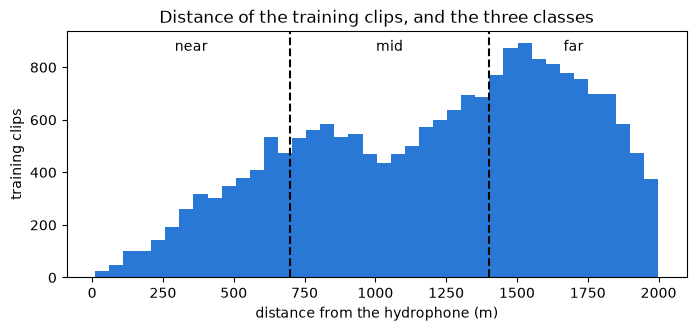

In [2]:
rows = {s: D.select_rows(table, fold=FOLD, split=s, task="distance") for s in D.SPLITS}
rng = np.random.default_rng(SEED)
if len(rows["train"]) > MAX_TRAIN:
    rows["train"] = np.sort(rng.choice(rows["train"], MAX_TRAIN, replace=False))

t0 = time.time()
X = {s: features_for(mel, r) for s, r in rows.items()}
print(f"features: {time.time() - t0:.0f} s, {X['train'].shape[1]} numbers per clip")

BORDERS = [700, 1400]
NAMES = ["near", "mid", "far"]
dist = {s: table.mean_distance.to_numpy(float)[r] for s, r in rows.items()}
y = {s: np.digitize(d, BORDERS) for s, d in dist.items()}

counts = pd.DataFrame({s: pd.Series(y[s]).value_counts().sort_index().set_axis(NAMES) for s in D.SPLITS})
counts.loc["ships"] = [table.MMSI.iloc[r].nunique() for r in rows.values()]
print(counts)

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(dist["train"], bins=40, color="#2a78d6")
for b in BORDERS:
    ax.axvline(b, color="k", ls="--")
for x, name in zip([350, 1050, 1700], NAMES):
    ax.text(x, ax.get_ylim()[1] * 0.92, name, ha="center")
ax.set_xlabel("distance from the hydrophone (m)"); ax.set_ylabel("training clips")
ax.set_title("Distance of the training clips, and the three classes"); plt.show()

The classes are not equally common, so plain accuracy can be inflated by always answering the biggest class.
We therefore also report **balanced accuracy** (the average of the per-class accuracies: random guessing gives
33 %) and **macro-F1** (lesson 03). Every model gets `class_weight="balanced"`, so rare classes count as much
as common ones during training.

In [3]:
def scores(true, pred):
    return {"accuracy": accuracy_score(true, pred), "balanced accuracy": balanced_accuracy_score(true, pred),
            "macro-F1": f1_score(true, pred, average="macro")}


majority = np.bincount(y["train"]).argmax()
guess = {"always guess the most common class": scores(y["test"], np.full(len(y["test"]), majority))}
print(pd.DataFrame(guess).T.round(3))

                                    accuracy  balanced accuracy  macro-F1
always guess the most common class     0.439              0.333     0.203


## 2. Three classifiers

The same three models as lesson 03, now with near / mid / far as the classes:

- **Logistic regression:** one weighted sum of the features per class (straight-line borders).
- **Random forest:** hundreds of decision trees, each on a random part of the data, voting.
- **Gradient boosting:** trees added one at a time, each fixing the previous trees' mistakes.

They are compared on the **validation** ships. The test ships are only used for the chosen model (section 3),
so its test score is not flattered by the choice.

validation ships:
                     accuracy  balanced accuracy  macro-F1  seconds
logistic regression     0.536              0.554     0.491   74.850
random forest           0.516              0.486     0.466   32.977
gradient boosting       0.551              0.534     0.516   79.510

chosen on validation: logistic regression


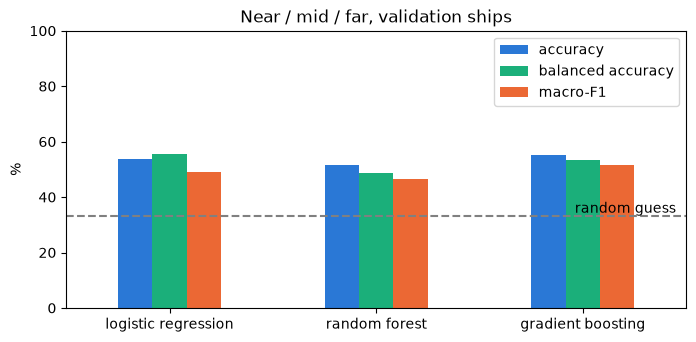

In [4]:
models = {
    "logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
    "random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                                            n_jobs=4, random_state=SEED),
    "gradient boosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
}
val = {}
for name, model in models.items():
    t0 = time.time()
    model.fit(X["train"], y["train"])
    val[name] = scores(y["validation"], model.predict(X["validation"]))
    val[name]["seconds"] = time.time() - t0
val = pd.DataFrame(val).T
print("validation ships:"); print(val.round(3))

best = val["balanced accuracy"].idxmax()
print(f"\nchosen on validation: {best}")

ax = val[["accuracy", "balanced accuracy", "macro-F1"]].mul(100).plot.bar(figsize=(8, 3.6), rot=0,
                                                                           color=["#2a78d6", "#1baf7a", "#eb6834"])
ax.axhline(100 / 3, ls="--", color="grey"); ax.text(2.45, 100 / 3 + 1, "random guess", ha="right")
ax.set_ylabel("%"); ax.set_ylim(0, 100); ax.set_title("Near / mid / far, validation ships"); plt.show()

## 3. The chosen model on the test ships

For comparison, the same gradient boosting trained as **regression** (lesson 03's baseline: predict the metres,
then sort the prediction into near / mid / far). Is it better to learn the classes directly, or the number?

test ships:
                                           accuracy  balanced accuracy  \
always guess the most common class            0.439              0.333   
logistic regression (classifier)              0.553              0.575   
gradient boosting regression, then binned     0.597              0.576   

                                           macro-F1  
always guess the most common class            0.203  
logistic regression (classifier)              0.544  
gradient boosting regression, then binned     0.601  


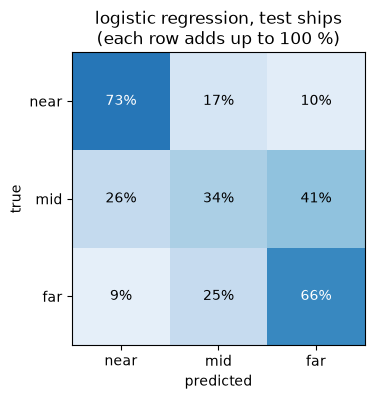

In [5]:
reg = HistGradientBoostingRegressor(loss="absolute_error", random_state=SEED).fit(X["train"], dist["train"])
reg_pred = {s: reg.predict(X[s]) for s in ("validation", "test")}

test = dict(guess)
test[f"{best} (classifier)"] = scores(y["test"], models[best].predict(X["test"]))
test["gradient boosting regression, then binned"] = scores(y["test"], np.digitize(reg_pred["test"], BORDERS))
test = pd.DataFrame(test).T
print("test ships:"); print(test.round(3))

cm = confusion_matrix(y["test"], models[best].predict(X["test"]), normalize="true")
fig, ax = plt.subplots(figsize=(4.6, 3.8))
ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{cm[i, j]:.0%}", ha="center", va="center", color="white" if cm[i, j] > 0.5 else "black")
ax.set_xticks(range(3), NAMES); ax.set_yticks(range(3), NAMES)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"{best}, test ships\n(each row adds up to 100 %)")
plt.show()

## 4. Finer classes: 250 m bins

Eight classes: 0-250 m, 250-500 m, ..., and 1,750 m or more (the same bins as lesson 11's "distance as
classes"). A gradient-boosting classifier learns the bins directly; the regression from section 3 is binned
afterwards. "Right bin or the next one" forgives a near miss.

(The regression's mean error can differ by a metre or two from lesson 03's 274 m: a different random set of
20,000 training clips is drawn.)

In [6]:
WIDTH, N_BINS = 250.0, 8
to_bin = lambda d: np.clip(np.floor(np.asarray(d) / WIDTH), 0, N_BINS - 1).astype(int)
yb = {s: to_bin(d) for s, d in dist.items()}

clf8 = HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED).fit(X["train"], yb["train"])
clf8_unweighted = HistGradientBoostingClassifier(random_state=SEED).fit(X["train"], yb["train"])


def bin_scores(true_bin, pred_bin):
    return {"right bin": np.mean(true_bin == pred_bin), "right bin or the next": np.mean(np.abs(true_bin - pred_bin) <= 1),
            "balanced accuracy": balanced_accuracy_score(true_bin, pred_bin)}


fine = pd.DataFrame({
    "always guess the median distance": bin_scores(yb["test"], np.full(len(yb["test"]), to_bin(np.median(dist["train"])))),
    "classifier, 8 bins (balanced)": bin_scores(yb["test"], clf8.predict(X["test"])),
    "classifier, 8 bins (not balanced)": bin_scores(yb["test"], clf8_unweighted.predict(X["test"])),
    "regression, then binned": bin_scores(yb["test"], to_bin(reg_pred["test"])),
}).T
print("test ships, 250 m bins:"); print(fine.round(3))
print(f"\nregression mean error: {np.mean(np.abs(reg_pred['test'] - dist['test'])):.0f} m "
      f"(always guessing the median: {np.mean(np.abs(np.median(dist['train']) - dist['test'])):.0f} m)")

test ships, 250 m bins:
                                   right bin  right bin or the next  \
always guess the median distance       0.192                  0.541   
classifier, 8 bins (balanced)          0.293                  0.662   
classifier, 8 bins (not balanced)      0.291                  0.686   
regression, then binned                0.282                  0.702   

                                   balanced accuracy  
always guess the median distance               0.125  
classifier, 8 bins (balanced)                  0.324  
classifier, 8 bins (not balanced)              0.298  
regression, then binned                        0.270  

regression mean error: 275 m (always guessing the median: 403 m)


## 5. Clustering

Clustering gets **no distances at all**. k-means puts every clip in one of k groups so that clips in the same
group have similar features. We first scale the 257 features and keep the 20 strongest directions of variation
(PCA), then ask for 3 groups, the same number as our distance classes.

If loudness and sound shape were mainly set by distance, the groups would line up with near / mid / far.
Two scores measure the match, both 0 for no relation and 1 for a perfect match:
**adjusted Rand index** (do pairs of clips that share a group also share a class?) and **normalised mutual
information** (how much knowing the group tells you about the class). We compare the groups with three things
they might follow instead: distance class, ship type and which hydrophone recorded the clip.

In [7]:
pca = make_pipeline(StandardScaler(), PCA(n_components=20, random_state=SEED)).fit(X["train"])
Z = {s: pca.transform(X[s]) for s in ("train", "test")}
info = {"ship type": table.label.to_numpy(), "hydrophone": table.hydrophone.astype(str).to_numpy()}

match = {}
for k in (3, 8):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z["train"])
    groups = km.predict(Z["test"])
    target = y["test"] if k == 3 else yb["test"]
    match[f"k = {k}: distance ({'near / mid / far' if k == 3 else '250 m bins'})"] = {
        "adjusted Rand": adjusted_rand_score(target, groups), "NMI": normalized_mutual_info_score(target, groups)}
    for what, col in info.items():
        match[f"k = {k}: {what}"] = {"adjusted Rand": adjusted_rand_score(col[rows["test"]], groups),
                                     "NMI": normalized_mutual_info_score(col[rows["test"]], groups)}
    if k == 3:
        km3, groups3 = km, groups
print("test ships, how well the groups match:"); print(pd.DataFrame(match).T.round(3))

test ships, how well the groups match:
                                    adjusted Rand    NMI
k = 3: distance (near / mid / far)          0.089  0.085
k = 3: ship type                            0.021  0.036
k = 3: hydrophone                          -0.011  0.051
k = 8: distance (250 m bins)                0.035  0.091
k = 8: ship type                            0.025  0.063
k = 8: hydrophone                           0.031  0.071


A clustering can also be turned into a classifier: give each group the distance class most common among its
training clips, then score the test clips.

                                    accuracy  balanced accuracy  macro-F1
k-means (3 groups) as a classifier     0.483              0.515     0.455

class given to each group: {0: 'far', 1: 'near', 2: 'mid'}


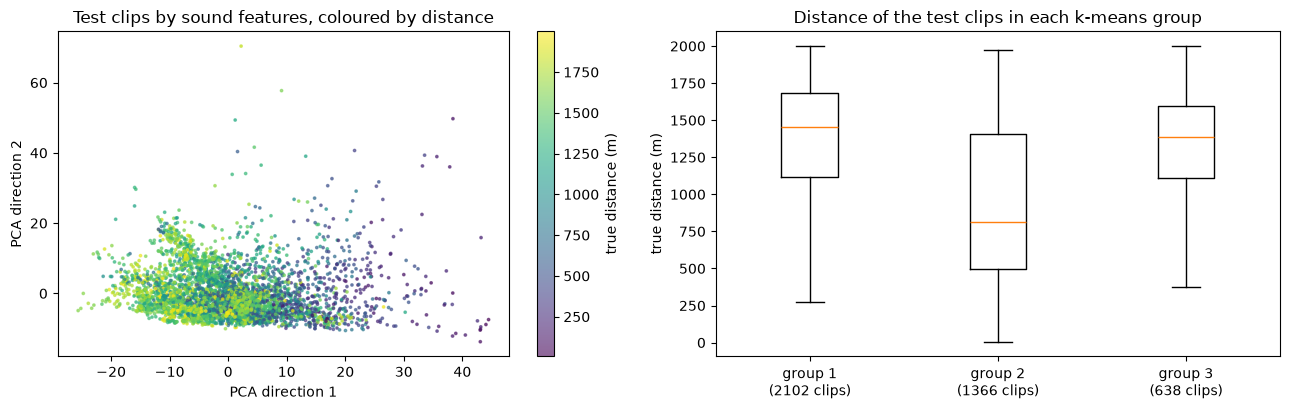

In [8]:
train_groups = km3.predict(Z["train"])
group_class = {g: np.bincount(y["train"][train_groups == g], minlength=3).argmax() for g in range(3)}
pred_from_groups = np.array([group_class[g] for g in groups3])
print(pd.DataFrame({"k-means (3 groups) as a classifier": scores(y["test"], pred_from_groups)}).T.round(3))
print("\nclass given to each group:", {g: NAMES[c] for g, c in group_class.items()})

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
sc = ax[0].scatter(Z["test"][:, 0], Z["test"][:, 1], c=dist["test"], s=3, cmap="viridis", alpha=0.6)
plt.colorbar(sc, ax=ax[0], label="true distance (m)")
ax[0].set_xlabel("PCA direction 1"); ax[0].set_ylabel("PCA direction 2")
ax[0].set_title("Test clips by sound features, coloured by distance")
ax[1].boxplot([dist["test"][groups3 == g] for g in range(3)], showfliers=False)
ax[1].set_xticks(range(1, 4), [f"group {g + 1}\n({(groups3 == g).sum()} clips)" for g in range(3)])
ax[1].set_ylabel("true distance (m)"); ax[1].set_title("Distance of the test clips in each k-means group")
plt.tight_layout(); plt.show()

## 6. What it means

The numbers below are recomputed by the last cell; the text was written from them (fold 1, seed 0).

- **Near / mid / far works moderately well without a CNN.** On ships never heard in training, the logistic
  regression classifier is right 55 % of the time (balanced accuracy 57.5 %), against 44 % (33 %) for always
  answering "far". Near ships are recognised best (73 % of them), far ships next (66 %). Mid is the hardest
  (34 %): it borders both other classes.
- **The three classifiers are close.** Logistic regression won on validation (balanced accuracy 55.4 % against
  53.4 % for gradient boosting and 48.6 % for random forest), but the differences are small.
- **Learning the classes directly is no better than learning the number.** Gradient boosting regression, sorted
  into the same three classes afterwards, does as well (accuracy 59.7 %, balanced 57.6 %). With 250 m bins the
  direct classifier finds the right bin a little more often (29.3 % against 28.2 %), the regression is more
  often right or one bin off (70.2 % against 66.2 %).
- **Clustering finds distance only weakly.** Given no distances at all, k-means' three groups follow distance
  a little (NMI 0.085), more than ship type (0.036) or hydrophone (0.051): loudness, which falls with distance,
  is the biggest difference between clips. As a classifier it reaches 48 % accuracy (52 % balanced): better than
  guessing, worse than the supervised models. One group gathers most of the near ships; the other two are both
  mostly far.
- **Why about 55-60 % is the ceiling here:** loudness depends on distance, but also on how loud the ship is (a
  big tanker far away can sound like a small boat nearby) and on the hydrophone. These features don't know the
  ship type, so they can't judge "loud for a tanker" (lesson 09).

In [9]:
b = test.loc[f"{best} (classifier)"]
r = test.loc["gradient boosting regression, then binned"]
g = test.loc["always guess the most common class"]
mt = pd.DataFrame(match).T["NMI"]
print(f"""Near / mid / far, test ships ({len(y['test'])} clips from {table.MMSI.iloc[rows['test']].nunique()} ships never heard in training):
  {best} classifier: accuracy {b['accuracy']:.1%}, balanced accuracy {b['balanced accuracy']:.1%}
  gradient boosting regression, then binned: accuracy {r['accuracy']:.1%}, balanced accuracy {r['balanced accuracy']:.1%}
  always the most common class: accuracy {g['accuracy']:.1%}, balanced accuracy {g['balanced accuracy']:.1%}
250 m bins: classifier right bin {fine.loc['classifier, 8 bins (balanced)', 'right bin']:.1%}, regression then binned {fine.loc['regression, then binned', 'right bin']:.1%}
k-means, 3 groups (NMI, 0 = no relation): distance {mt.iloc[0]:.3f}, ship type {mt.iloc[1]:.3f}, hydrophone {mt.iloc[2]:.3f}""")

Near / mid / far, test ships (4106 clips from 527 ships never heard in training):
  logistic regression classifier: accuracy 55.3%, balanced accuracy 57.5%
  gradient boosting regression, then binned: accuracy 59.7%, balanced accuracy 57.6%
  always the most common class: accuracy 43.9%, balanced accuracy 33.3%
250 m bins: classifier right bin 29.3%, regression then binned 28.2%
k-means, 3 groups (NMI, 0 = no relation): distance 0.085, ship type 0.036, hydrophone 0.051
